# 02 · Alignment and physical covariates

**Question.** Can forecasts, satellite features and the target be put on one grid and one time axis without moving water or leaking the future, and do satellite features carry a signal ahead of rain?

**Method.** Forecast members are remapped conservatively from 0.25° to 0.1° and checked against an independent integral; every input enters as of the issue time with its publication delay; satellite features come from the June–August 2025 hourly frames and are correlated with rain onsets in the target, by terrain stratum.

**Answer.** Remapping keeps the total within 3 × 10⁻¹⁰ (relative) over 510 fields. Cooling of cloud tops goes with rain onsets in the onset hour and the hour before (correlation −0.06 to −0.11 in every stratum, 70,021 onsets) and vanishes from three hours ahead. That window is also where the target reuses the same satellite frames, so the signal is real for nowcasting but not proven independent of the target.

In [1]:
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from arena.config import load_config
from arena.data import cache
from arena.data.align import nwp_as_of, six_hour_totals
from arena.data.grid import cell_areas, common_grid, conservative_regrid
from arena.data.region import Region
from arena.data.sampling import STRATA, strata
from arena.data.sources.aifs_ens import deaccumulate
from arena.nwp.covariates import forecast_covariates
from arena.physics.base import covariates
from arena.physics.onset import lagged_correlation, onsets

cfg = load_config()
root = cache.cache_root(cfg)
region = Region.from_config(cfg.region)
lat, lon = common_grid(region, cfg.data.grid_step)
plt.rcParams.update(
    {"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9}
)
pd.options.display.float_format = "{:,.3f}".format

## 1. Forecasts on the common grid: is mass conserved?

Forecast totals come on a 0.25° grid and are remapped conservatively to the
0.1° grid of the target: each fine cell takes the area-weighted mean of the
coarse cells it overlaps. The check below does not reuse the regridding
weights. It splits every coarse cell into 50 × 50 sub-cells, keeps those
inside the fine grid's outer edges, and integrates precipitation times area
directly. Both integrals should agree for every member and step.

In [2]:
runs = cache.open_cached(cfg, "aifs_ens")
totals = deaccumulate(runs[["tp"]]).load()
run = totals.tp.sel(init_time="2026-06-01T00:00")
fine = conservative_regrid(run, lat, lon)

k = 50
step = 0.25
offsets = (np.arange(k) + 0.5) * step / k - step / 2
sub_lat = (run.latitude.values[:, None] + offsets[None, :]).ravel()
sub_lon = (run.longitude.values[:, None] + offsets[None, :]).ravel()
inside_lat = (sub_lat > lat[0] - 0.05) & (sub_lat < lat[-1] + 0.05)
inside_lon = (sub_lon > lon[0] - 0.05) & (sub_lon < lon[-1] + 0.05)
sub_area = np.radians(step / k) ** 2 * np.cos(np.radians(sub_lat[inside_lat]))[:, None]
area = cell_areas(fine).values

errors = []
for member in run.member.values:
    for s in run.step.values:
        coarse = run.sel(member=member, step=s).values
        upsampled = np.repeat(np.repeat(coarse, k, axis=0), k, axis=1)[inside_lat][
            :, inside_lon
        ]
        before = (upsampled * sub_area).sum()
        after = (fine.sel(member=member, step=s).values * area).sum()
        errors.append(abs(after - before) / before)
print(
    f"{len(errors)} fields (51 members x 10 steps); largest relative difference {max(errors):.1e}"
)

510 fields (51 members x 10 steps); largest relative difference 3.2e-10


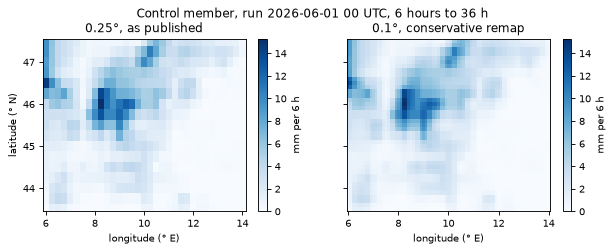

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
field = dict(member=0, step=36)
vmax = float(run.sel(**field).max())
run.sel(**field).plot(
    ax=axes[0], vmin=0, vmax=vmax, cmap="Blues", cbar_kwargs={"label": "mm per 6 h"}
)
fine.sel(**field).plot(
    ax=axes[1], vmin=0, vmax=vmax, cmap="Blues", cbar_kwargs={"label": "mm per 6 h"}
)
axes[0].set_title("0.25°, as published")
axes[1].set_title("0.1°, conservative remap")
for ax in axes:
    ax.set_xlabel("longitude (° E)")
axes[0].set_ylabel("latitude (° N)")
axes[1].set_ylabel("")
fig.suptitle("Control member, run 2026-06-01 00 UTC, 6 hours to 36 h", y=1.02)
plt.show()

## 2. What a forecaster may see at an issue time

Every input enters "as of" the issue time *t*, with the delays below. The
leakage tests in `tests/test_align.py` and `tests/test_sampling.py` sweep issue
times and check each rule.

| Input | Usable at issue time *t* | Why |
|---|---|---|
| Forecast run | newest run started at or before *t* − 12 h | dissemination takes about 7–8 h, with late arrivals |
| Satellite frame | frames up to *t* − 60 min | measured publication latency |
| Target history | frames up to *t* (hindcast); *t* − 90 min in the sensitivity run | the target looks 90 min ahead |
| Sample split | its 48 h of targets stay inside its window | embargo between windows |

With runs at 00 and 12 UTC archived to 60 h, issue times at 00 and 12 UTC
reach a 48 h lead. The table shows which run and which steps serve the issue
2026-06-02 00 UTC.

In [4]:
issue = datetime(2026, 6, 2, 0)
leads = list(cfg.data.align.regime_b.leads_hours)
forecast = nwp_as_of(totals, issue, leads, cfg)
valid_end = pd.Timestamp(issue) + pd.to_timedelta(forecast.lead.values, unit="h")
pd.DataFrame(
    {
        "lead (h)": forecast.lead.values,
        "run": pd.Timestamp(forecast.init_time.values).strftime("%Y-%m-%d %H UTC"),
        "step (h)": forecast.step.values,
        "window": [
            f"{(e - pd.Timedelta(hours=6)):%d %H:%M} – {e:%d %H:%M}" for e in valid_end
        ],
    }
).set_index("lead (h)")

,run,step (h),window
lead (h),,,
6,2026-06-01 12 UTC,18,02 00:00 – 02 06:00
12,2026-06-01 12 UTC,24,02 06:00 – 02 12:00
18,2026-06-01 12 UTC,30,02 12:00 – 02 18:00
24,2026-06-01 12 UTC,36,02 18:00 – 03 00:00
30,2026-06-01 12 UTC,42,03 00:00 – 03 06:00
36,2026-06-01 12 UTC,48,03 06:00 – 03 12:00
42,2026-06-01 12 UTC,54,03 12:00 – 03 18:00
48,2026-06-01 12 UTC,60,03 18:00 – 04 00:00


Per-pixel covariates of that run: members are remapped first, then the
ensemble statistics are taken (quantiles do not commute with averaging).

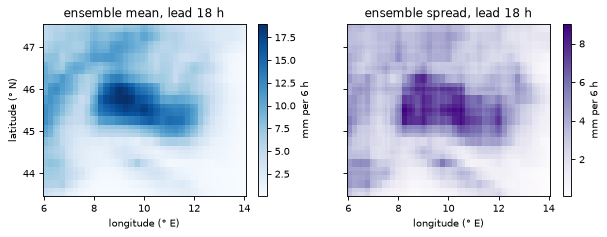

In [5]:
nwp = forecast_covariates(totals, issue, leads, cfg, ["aifs_ens"])
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
nwp.sel(feature="tp_mean", lead=18).plot(
    ax=axes[0], cmap="Blues", cbar_kwargs={"label": "mm per 6 h"}
)
nwp.sel(feature="tp_spread", lead=18).plot(
    ax=axes[1], cmap="Purples", cbar_kwargs={"label": "mm per 6 h"}
)
axes[0].set_title("ensemble mean, lead 18 h")
axes[1].set_title("ensemble spread, lead 18 h")
for ax in axes:
    ax.set_xlabel("longitude (° E)")
axes[0].set_ylabel("latitude (° N)")
axes[1].set_ylabel("")
plt.show()

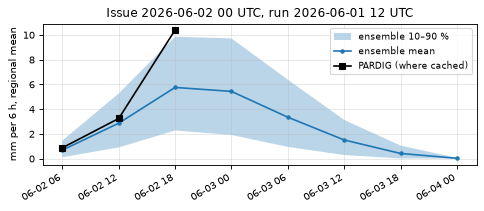

In [6]:
rain = cache.open_cached(cfg, "pardig").precipitation
observed = six_hour_totals(
    rain.sel(time=slice("2026-06-01", "2026-06-03")).load(), step_minutes=15
)
regional = nwp.mean(("latitude", "longitude"))
seen = observed.mean(("latitude", "longitude")).reindex(time=valid_end)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.fill_between(
    valid_end,
    regional.sel(feature="tp_q10"),
    regional.sel(feature="tp_q90"),
    alpha=0.3,
    label="ensemble 10–90 %",
)
ax.plot(valid_end, regional.sel(feature="tp_mean"), marker=".", label="ensemble mean")
ax.plot(valid_end, seen, marker="s", color="black", label="PARDIG (where cached)")
ax.set_ylabel("mm per 6 h, regional mean")
ax.set_title("Issue 2026-06-02 00 UTC, run 2026-06-01 12 UTC")
ax.legend(loc="upper right", fontsize=8)
fig.autofmt_xdate()
plt.show()

## 3. Physical covariates from the satellite

Summer 2025 (June to August), hourly. `bt_ir` is the 11.2 µm window
temperature, close to the cloud-top temperature for thick cloud; `bt_diff`
(window minus 6.2 µm water vapour) approaches zero or turns negative for deep
convective tops; `dbt_dt` is the change of the window temperature over the
previous hour, strongly negative for growing tops. `dbt_dt` uses no frame
after its time. Solar geometry is computed, so it is known for any future
time.

In [7]:
sat = (
    cache.open_cached(cfg, "satweave")
    .sel(time=slice("2025-06-01", "2025-08-31"))
    .load()
)
features = covariates(sat, ["radiative", "solar"])
hours = sat.sizes["time"]
print(
    f"{hours} hours ({hours / 24:.0f} days), {sat.sizes['latitude']} x {sat.sizes['longitude']} cells"
)
print(
    "features:",
    ", ".join(
        f"{f}{' (known ahead)' if k else ''}"
        for f, k in zip(
            features.feature.values, features.known_future.values, strict=True
        )
    ),
)

2208 hours (92 days), 41 x 81 cells
features: bt_ir, bt_wv, bt_diff, dbt_dt, cos_zenith (known ahead), doy_sin (known ahead), doy_cos (known ahead), hour_sin (known ahead), hour_cos (known ahead)


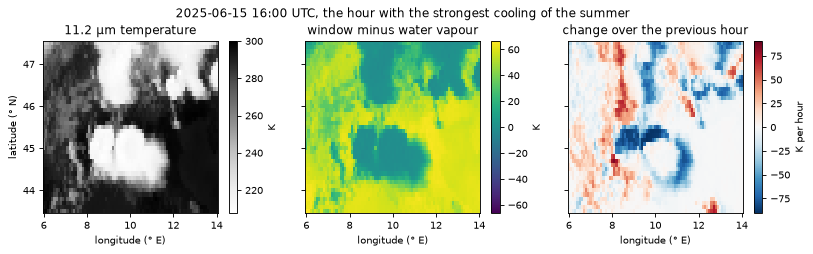

In [8]:
rate = features.sel(feature="dbt_dt")
strongest = (
    rate.dropna("time", how="all")
    .quantile(0.01, dim=("latitude", "longitude"))
    .idxmin("time")
)
when = pd.Timestamp(strongest.values)
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
features.sel(feature="bt_ir", time=when).plot(
    ax=axes[0], cmap="Greys", cbar_kwargs={"label": "K"}
)
features.sel(feature="bt_diff", time=when).plot(
    ax=axes[1], cmap="viridis", cbar_kwargs={"label": "K"}
)
rate.sel(time=when).plot(
    ax=axes[2], cmap="RdBu_r", center=0, cbar_kwargs={"label": "K per hour"}
)
for ax, title in zip(
    axes,
    [
        "11.2 µm temperature",
        "window minus water vapour",
        "change over the previous hour",
    ],
    strict=True,
):
    ax.set_title(title)
    ax.set_xlabel("longitude (° E)")
axes[0].set_ylabel("latitude (° N)")
for ax in axes[1:]:
    ax.set_ylabel("")
fig.suptitle(
    f"{when:%Y-%m-%d %H:%M} UTC, the hour with the strongest cooling of the summer",
    y=1.03,
)
plt.show()

## 4. Does cloud-top cooling come before rain?

An onset is an hour with at least 1 mm/h after two hours below 0.1 mm/h, at
a cell. The figure shows, for each terrain stratum, the correlation between
the cooling rate *lag* hours earlier and the onset indicator. A negative
value at positive lags means cooling tends to precede onsets.

**Caveat.** The target at time *s* is estimated from satellite frames between
*s* − 120 min and *s* + 90 min. A cooling rate *lag* hours before an onset
uses frames at *t* − *lag* and *t* − *lag* − 1 h, so for lags up to 2 h those
frames are inputs of the target itself, and part of the correlation there is
built in. Only lags of 3 h and more compare independent data (grey band:
shared frames).

In [9]:
rain_hourly = rain.sel(time=sat.time).load()
started = onsets(rain_hourly, threshold=1.0, dry=0.1, dry_hours=2)
elevation = xr.open_zarr(
    root / "static" / "elevation.zarr", consolidated=False
).elevation.load()
labels = strata(elevation, cfg)
lags = list(range(-3, 7))
curves, counts = {}, {}
for index, name in enumerate(STRATA):
    cells = labels == index
    curves[name] = lagged_correlation(rate.where(cells), started.where(cells), lags)
    counts[name] = int(started.where(cells, False).sum())
table = pd.DataFrame({name: curve.to_series() for name, curve in curves.items()}).T
table.insert(0, "onsets", pd.Series(counts))
table

lag,onsets,-3,-2,-1,0,1,2,3,4,5,6
sea,7684,0.042,0.057,0.058,-0.064,-0.097,-0.037,-0.006,-0.004,-0.010,-0.009
coast,5281,0.035,0.041,0.057,-0.073,-0.109,-0.041,-0.009,-0.004,-0.010,-0.001
plains,10113,0.045,0.050,0.046,-0.077,-0.109,-0.033,-0.004,-0.002,-0.007,-0.009
pre_alps,22418,0.033,0.040,0.046,-0.097,-0.090,-0.018,-0.003,-0.004,-0.002,-0.003
alps,25525,0.028,0.032,0.035,-0.100,-0.095,-0.023,-0.010,-0.009,-0.005,-0.002


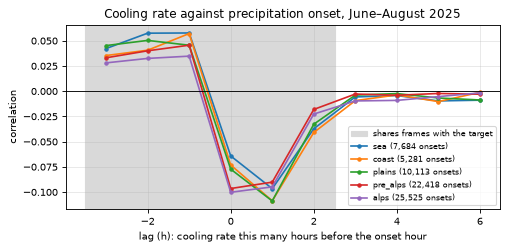

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.axvspan(lags[0] - 0.5, 2.5, color="0.85", label="shares frames with the target")
for name, curve in curves.items():
    ax.plot(curve.lag, curve, marker=".", label=f"{name} ({counts[name]:,} onsets)")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("lag (h): cooling rate this many hours before the onset hour")
ax.set_ylabel("correlation")
ax.set_title("Cooling rate against precipitation onset, June–August 2025")
ax.legend(fontsize=7, loc="lower right")
plt.show()

Every stratum shows the same shape. Cooling goes with onsets in the onset
hour and the hour before (correlations of −0.06 to −0.11), weakly two hours
before, and not at all from three hours on (|r| ≤ 0.01). After onsets the
tops warm (positive values at negative lags). The correlations are small
because onsets are rare and each one is a single cell-hour, but with 70,000
onsets the shape is clear.

So the satellite covariates track rain as it starts, which is what a
nowcast at short leads needs, but this check cannot separate that from the
target's own use of the same frames: the whole signal sits in the grey band.
Beyond it, at three hours and more, a cell's cooling says nothing about its
own onset. Any lead time gained from the covariates in regime A has to be
shown by the sensitivity run, not assumed from this figure.

## 5. What this means for the models

- Forecast totals can be put on the target grid without creating or losing
  water; the same remap serves every model that uses forecast covariates.
- Each input has an explicit publication delay, and the tests check that no
  join can return data from after its delay.
- Cloud-top cooling and rain onsets go together within about two hours, in
  every stratum, and are unrelated beyond three hours at the same cell. That
  window is also where the target reuses the satellite frames, so the
  nowcasting results are read together with the 90-minute sensitivity run.
  Cooling upwind of a cell, which could carry information over longer leads,
  is not tested here.